# Short-Term PM2.5 Forecasting for Delhi: Do NO2, Weather and Fires Help?

**Group B15 · IT462 EDA · Prediction part (Abhijeet Kujur, 202401006)**

**Question.** Can Delhi's PM2.5 be forecast 1–3 hours and one day ahead, do ML models beat a simple persistence baseline, and do NO2, weather and fire features add anything?

**Data (from the repo's `data/raw/`).** OpenAQ hourly PM2.5 and NO2 (one station), Open-Meteo hourly weather (ends 31 Aug 2025), NASA FIRMS VIIRS fire detections. Study window: 1 Mar – 30 Nov 2025.

**How this notebook relates to the rest of the project.** Yashvi's `pollution_model_a` / `combined_analysis` notebooks already forecast *daily* PM2.5 with pollution-only (Model A) and pollution+fire (Model C) features. This notebook (i) adds *hourly* 1–3 h forecasts, where the weather data can be used; (ii) tests NO2, weather and fire additions against persistence with confidence intervals; (iii) predicts exceedance of the 60 µg/m³ standard (classification, as in Lab 11); and (iv) re-runs the daily forecast on the same walk-forward idea so the results can be compared with Model A/C.

**Lab concepts used.** Lab 9 (missing values, outliers, feature engineering), Lab 10 (time-series → supervised table, lags, chronological split, persistence baseline, Linear/Tree/RF), Lab 11 (classification: lazy baseline, precision/recall/F1, confusion matrix, Logistic/Tree/RF), Assignment 6 (scaling pipelines).

**Conventions.** `random_state=42` everywhere; data is never shuffled; scaling and imputation are learned from training data only; every plot is titled and labelled.


## 0. Setup

In [1]:
import warnings, json; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.dates as mdates, seaborn as sns
from scipy import stats
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25, "axes.spines.top": False, "axes.spines.right": False})
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()   # repo root
RAW = ROOT / "data" / "raw"
print("raw files:", sorted(p.name for p in RAW.rglob("*.csv")))

raw files: ['firms_noaa20_2025_mar_nov.csv', 'no2_hourly_mar_nov.csv', 'pm25_hourly_mar_nov.csv', 'weather_hourly.csv']


## 1. Load the raw data and build a regular hourly series (Lab 9 / Lab 10 Q1)
The raw air-quality exports list only the hours that were reported, so missing hours are simply *absent*. We reindex to a complete hourly calendar (1 Mar 05:00 → 1 Dec 04:00 IST) so that gaps become visible `NaN`s and lags/rolling windows mean what they say.

**Assumptions (same as in Yashvi's cleaning notebook):** local timestamps are used as-is; three NO2 readings of exactly 0 ppb are treated as sensor-floor errors and set to missing; gaps of at most 6 hours *inside* the series are filled by time interpolation, longer gaps are left missing. **The forecast target is never an interpolated value** — we keep an `*_obs` copy of the untouched readings and only score predictions against those.

In [2]:
def read_aq(name):
    d = pd.read_csv(RAW / "air_quality" / f"{name}_hourly_mar_nov.csv")
    d["t"] = pd.to_datetime(d["datetime_from_local"].str[:19])        # local clock time, offset dropped
    return d.drop_duplicates("t").set_index("t")["value"]

HOURS = pd.date_range("2025-03-01 05:00", "2025-12-01 04:00", freq="h")
pm_obs  = read_aq("pm25").reindex(HOURS)
no2_obs = read_aq("no2").reindex(HOURS)
print("calendar hours:", len(HOURS))
print("PM2.5 rows reported:", pm_obs.notna().sum(), "| missing:", pm_obs.isna().sum(), f"({pm_obs.isna().mean():.1%})")
print("NO2   rows reported:", no2_obs.notna().sum(), "| missing:", no2_obs.isna().sum(), f"({no2_obs.isna().mean():.1%})")
print("NO2 readings equal to 0:", int((no2_obs == 0).sum()))
no2_obs = no2_obs.mask(no2_obs == 0)

def run_lengths(s):
    m = s.isna().astype(int); g = (m.diff() != 0).cumsum()
    r = m.groupby(g).agg(["first", "size"]); return r[r["first"] == 1]["size"]
r = run_lengths(pm_obs)
print(f"PM2.5 gaps: {len(r)} runs, {int((r<=6).sum())} are <= 6 h, longest = {r.max()} h")

pm  = pm_obs.interpolate("time", limit=6, limit_area="inside")      # modelling copy
no2 = no2_obs.interpolate("time", limit=6, limit_area="inside")
print("PM2.5 hours filled by interpolation:", int(pm_obs.isna().sum() - pm.isna().sum()))

calendar hours: 6600
PM2.5 rows reported: 5910 | missing: 690 (10.5%)
NO2   rows reported: 5985 | missing: 615 (9.3%)
NO2 readings equal to 0: 3
PM2.5 gaps: 94 runs, 66 are <= 6 h, longest = 60 h
PM2.5 hours filled by interpolation: 298


> **Observation:** The calendar has 6,600 hours; PM2.5 is missing in 690 of them (10.5%) and NO2 in 615 (9.3%). The 690 PM2.5 gaps form 94 runs, of which 66 are 6 hours or shorter; the longest outage is 60 hours. Only 298 hours were filled by interpolation, so about 90% of the series is real measurement. The three NO2 zeros were treated as missing. These numbers agree with Yashvi's cleaning notebook (same 690 / 615 missing hours).

## 2. What does the series look like? (Lab 10 Q2–Q3)

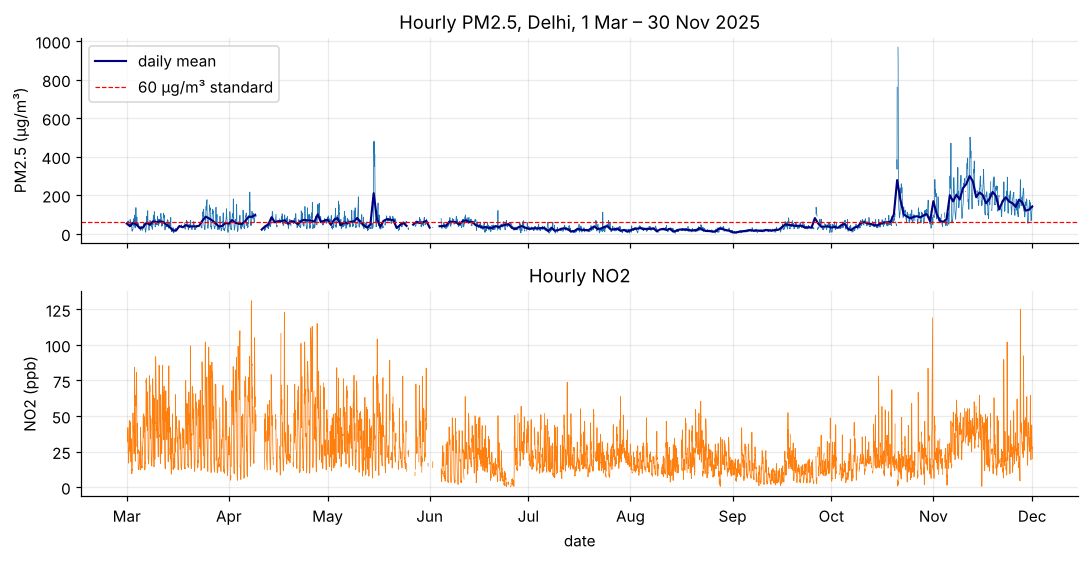

count    5910.0
mean       59.4
std        62.2
min         1.0
25%        23.5
50%        41.0
75%        69.0
max       968.0
Name: value, dtype: float64


In [3]:
fig, ax = plt.subplots(2, 1, figsize=(10, 5.2), sharex=True)
ax[0].plot(pm_obs, lw=.5, color="tab:blue"); ax[0].plot(pm_obs.resample("D").mean(), lw=1.4, color="navy", label="daily mean")
ax[0].axhline(60, color="red", ls="--", lw=.8, label="60 µg/m³ standard"); ax[0].set_ylabel("PM2.5 (µg/m³)"); ax[0].legend()
ax[0].set_title("Hourly PM2.5, Delhi, 1 Mar – 30 Nov 2025")
ax[1].plot(no2_obs, lw=.5, color="tab:orange"); ax[1].set_ylabel("NO2 (ppb)"); ax[1].set_title("Hourly NO2"); ax[1].set_xlabel("date")
ax[1].xaxis.set_major_formatter(mdates.DateFormatter("%b")); plt.tight_layout(); plt.show()
print(pm_obs.describe().round(1))

> **Observation:** PM2.5 follows a clear seasonal arc: moderate in March–May, lowest in the monsoon (July–August), then rising sharply in October–November (the daily mean line). The hourly series is very right-skewed (mean 59.4, median 41.0, maximum 968 µg/m³ on the Diwali night of 21 October), which is why we model ln PM2.5. The 60 µg/m³ line is crossed often in spring and almost every day in November.

ADF on ln PM2.5 (hourly): p = 0.0013


ADF on 24-h differences of ln PM2.5: p = 0.0


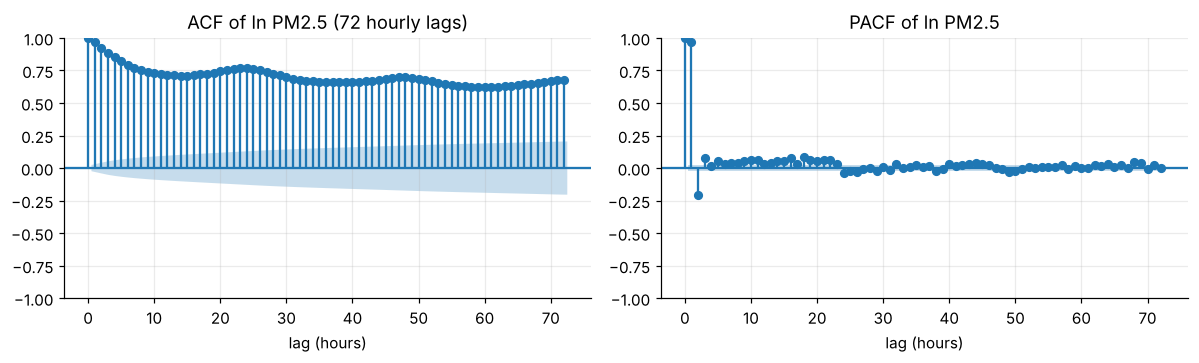

autocorrelation at lag 1, 3, 6, 12, 24 h: [np.float64(0.969), np.float64(0.887), np.float64(0.796), np.float64(0.716), np.float64(0.77)]


In [4]:
lnpm = np.log(pm)
blk = lnpm.loc["2025-03-01":"2025-11-30"].interpolate("time")        # fill remaining gaps only for these diagnostics
print("ADF on ln PM2.5 (hourly): p =", round(adfuller(blk.dropna())[1], 4))
print("ADF on 24-h differences of ln PM2.5: p =", round(adfuller(blk.diff(24).dropna())[1], 4))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
plot_acf(blk.dropna(), lags=72, ax=ax[0]); ax[0].set_title("ACF of ln PM2.5 (72 hourly lags)"); ax[0].set_xlabel("lag (hours)")
plot_pacf(blk.dropna(), lags=72, ax=ax[1], method="ywm"); ax[1].set_title("PACF of ln PM2.5"); ax[1].set_xlabel("lag (hours)")
plt.tight_layout(); plt.show()
print("autocorrelation at lag 1, 3, 6, 12, 24 h:", [round(blk.autocorr(k), 3) for k in (1, 3, 6, 12, 24)])

> **Observation:** PM2.5 is extremely persistent: the autocorrelation is 0.97 at 1 hour, 0.89 at 3 hours and 0.80 at 6 hours, with a secondary bump at 24 hours (0.77 vs 0.72 at 12 hours) from the daily cycle. This tells us that (i) the last few hours carry almost all the information for a 1–3 hour forecast, so lags 0–3 plus 6, 12 and 24 are the natural features, and (ii) persistence will be a very hard baseline. The ADF test rejects a unit root for the hourly series (p ≈ 0.001), but the series has a strong seasonal level shift, and Yashvi's ADF on the daily series did *not* reject (p ≈ 0.26), so we do not rely on stationarity and use the *change* in ln PM2.5 as a target for the tree models (Section 6).

## 3. Weather and fire data, and a coverage warning
Open-Meteo weather in the repo ends on **31 Aug 2025**, while PM2.5/NO2 run to 30 Nov. So any model that uses weather can only be trained and tested on 1 Mar – 31 Aug. Fire data (FIRMS) cover the whole period but are only meaningful on a *daily* scale.

In [5]:
w = pd.read_csv(RAW / "weather" / "weather_hourly.csv", parse_dates=["datetime_local"]).set_index("datetime_local")
print("weather rows:", len(w), "| from", w.index.min(), "to", w.index.max(), "| missing values:", int(w.isna().sum().sum()))
print(w.describe().round(1).T[["mean", "min", "max"]])
H = pd.DataFrame({"pm25_obs": pm_obs, "pm25": pm, "no2": no2}).join(w)
H["has_weather"] = H["temperature_2m"].notna()
print("hours with PM2.5, NO2 and weather all present:", int((H.has_weather & H.pm25_obs.notna() & H.no2.notna()).sum()))

weather rows: 4416 | from 2025-03-01 00:00:00 to 2025-08-31 23:00:00 | missing values: 0
                        mean    min     max
temperature_2m          29.2   12.5    43.1
relative_humidity_2m    58.1    5.0    99.0
wind_speed_10m           2.2    0.0     8.6
wind_direction_10m     172.7    3.0   360.0
precipitation            0.1    0.0    11.1
surface_pressure       976.9  966.0   991.5
boundary_layer_height  641.0   10.0  5220.0
hours with PM2.5, NO2 and weather all present: 3882


> **Observation:** The weather file has no missing values but ends on 31 August 2025, so the weather-based models can use only 3,882 hours (1 Mar – 31 Aug) that also have PM2.5 and NO2. This means **none of the hourly weather results say anything about October–November**, the most polluted months. This is the main limitation of the prediction part and is repeated in the summary.

## 4. Turning the series into a supervised table (Lab 10 Q4–Q6)
Each row is an hour *t*; inputs use information up to *t* only; the target is PM2.5 at *t+h* (h = 1, 2 or 3 hours). We work on the log scale (`ln PM2.5`), because PM2.5 is right-skewed (Lab 9) and errors are naturally proportional.

| Group | Features | Why |
|---|---|---|
| PM history (**A**) | lags 0,1,2,3,6,12,24 h; 3 h and 24 h rolling means; 3 h change | recent level and tendency (ACF above) |
| NO2 (**B**) | NO2 at t, t-1, t-3; 3 h mean | proxy for local combustion |
| Weather (**C**) | temperature, humidity, ln wind speed, wind u/v components, rain flag and 3 h sum, pressure and 3 h change, ln boundary-layer height and its 1 h change | dispersion and removal of pollutants |
| Calendar | sin/cos of hour, weekend flag | diurnal cycle |

Wind direction is circular, so it is converted to east-west (u) and north-south (v) components.

In [6]:
W = H[H.has_weather].copy()
W["lnpm"] = np.log(W.pm25); W["lnno2"] = np.log(W.no2)
th = np.radians(W.wind_direction_10m)
F = pd.DataFrame(index=W.index)
for L in (0, 1, 2, 3, 6, 12, 24): F[f"pm_lag{L}"] = W.lnpm.shift(L)
F["pm_roll3"] = W.lnpm.rolling(3).mean(); F["pm_roll24"] = W.lnpm.rolling(24).mean(); F["pm_diff3"] = W.lnpm - W.lnpm.shift(3)
for L in (0, 1, 3): F[f"no2_lag{L}"] = W.lnno2.shift(L)
F["no2_roll3"] = W.lnno2.rolling(3).mean()
F["temp"] = W.temperature_2m; F["rh"] = W.relative_humidity_2m; F["lnws"] = np.log(W.wind_speed_10m + .1)
F["wind_u"] = -W.wind_speed_10m*np.sin(th); F["wind_v"] = -W.wind_speed_10m*np.cos(th)
F["wet"] = (W.precipitation > 0).astype(float); F["rain3h"] = W.precipitation.rolling(3).sum()
F["press"] = W.surface_pressure; F["dpress3"] = W.surface_pressure - W.surface_pressure.shift(3)
F["lnblh"] = np.log(W.boundary_layer_height); F["dblh1"] = F["lnblh"] - F["lnblh"].shift(1)
F["hr_sin"] = np.sin(2*np.pi*W.index.hour/24); F["hr_cos"] = np.cos(2*np.pi*W.index.hour/24); F["weekend"] = (W.index.dayofweek >= 5).astype(float)

PM  = [c for c in F if c.startswith("pm_")]; NO = [c for c in F if c.startswith("no2_")]
WX  = ["temp","rh","lnws","wind_u","wind_v","wet","rain3h","press","dpress3","lnblh","dblh1"]; CAL = ["hr_sin","hr_cos","weekend"]
FEATSETS = {"A: PM history": PM + CAL, "B: A + NO2": PM + NO + CAL, "C: A + weather": PM + WX + CAL, "D: A + NO2 + weather": PM + NO + WX + CAL}

def hourly_frame(h):
    y = np.log(W.pm25_obs.shift(-h))                      # target: OBSERVED PM2.5 at t+h
    d = pd.concat([F, y.rename("y")], axis=1)
    return d, d.dropna()
d_raw, d3 = hourly_frame(3)
print("feature table for h=3: shape before dropna", d_raw.shape, "-> after dropna", d3.shape)
print("features per group:", {k: len(v) for k, v in dict(PM=PM, NO2=NO, weather=WX, calendar=CAL).items()})

feature table for h=3: shape before dropna (4411, 29) -> after dropna (3387, 29)
features per group: {'PM': 10, 'NO2': 4, 'weather': 11, 'calendar': 3}


> **Observation:** The weather window has 4,416 hours. With the 3-hour target the table has 4,411 rows before `dropna()` and 3,387 after. Rows are lost at the start (lag 24 and the 24-hour rolling mean need 24 earlier hours), at the end (the last 3 hours have no value 3 hours later), and, mostly, around missing readings: any hour whose target is a real missing value, or whose lags/rolling windows touch a gap longer than 6 hours, is removed. Interpolated values are never used as a target.

In [7]:
# Leakage check (Lab 10 Q5): one row from the middle, features vs raw series
mid = d3.index[len(d3)//2:]
t0 = next(t for t in mid if len({round(d3.loc[t, c], 4) for c in ("pm_lag0", "pm_lag1", "pm_lag2")}) == 3)   # a row where the values differ
print("row at", t0)
print("pm_lag1  :", round(d3.loc[t0, "pm_lag1"], 4), "| ln PM at t-1 from raw series:", round(np.log(W.pm25.loc[t0 - pd.Timedelta(hours=1)]), 4))
print("pm_roll3 :", round(d3.loc[t0, "pm_roll3"], 4), "| mean of ln PM at t-2..t :", round(np.log(W.pm25.loc[t0 - pd.Timedelta(hours=2): t0]).mean(), 4))
print("pm_lag0  :", round(d3.loc[t0, "pm_lag0"], 4), "| ln PM at t from raw series  :", round(np.log(W.pm25.loc[t0]), 4))
print("target y :", round(d3.loc[t0, "y"], 4), "| ln observed PM at t+3h       :", round(np.log(W.pm25_obs.loc[t0 + pd.Timedelta(hours=3)]), 4))


row at 2025-06-08 21:00:00
pm_lag1  : 3.9703 | ln PM at t-1 from raw series: 3.9703
pm_roll3 : 3.987 | mean of ln PM at t-2..t : 3.987
pm_lag0  : 4.0395 | ln PM at t from raw series  : 4.0395
target y : 4.3108 | ln observed PM at t+3h       : 4.3108


> **Observation:** Each feature equals the value computed from the raw series using only hours up to *t* (lag 1 is the previous hour, the 3-hour mean covers *t-2…t*), and the target is the observed ln PM2.5 three hours later. Nothing from *t+1* onward enters the inputs. Using a centred rolling window (`center=True`) would put future hours into the feature and make the model look far better than it could ever be in real use.

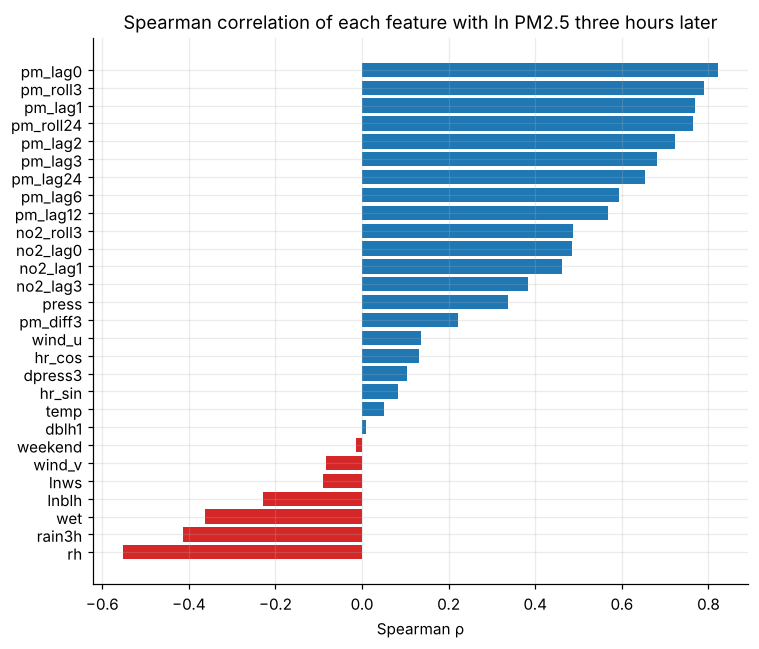

{'pm_lag2': 0.72, 'pm_roll24': 0.76, 'pm_lag1': 0.77, 'pm_roll3': 0.79, 'pm_lag0': 0.82}
{'rh': -0.55, 'rain3h': -0.41, 'wet': -0.36}
feature pairs with |r| > 0.95: 4


In [8]:
sp = pd.Series({c: stats.spearmanr(d3[c], d3.y)[0] for c in F.columns}).sort_values()
fig, ax = plt.subplots(figsize=(7, 6)); ax.barh(sp.index, sp.values, color=["tab:red" if v < 0 else "tab:blue" for v in sp.values])
ax.set_title("Spearman correlation of each feature with ln PM2.5 three hours later"); ax.set_xlabel("Spearman ρ"); plt.tight_layout(); plt.show()
print(sp.tail(5).round(2).to_dict()); print(sp.head(3).round(2).to_dict())
big = F[PM + NO].corr().abs().where(np.triu(np.ones((len(PM+NO),)*2), 1) > 0).stack(); print("feature pairs with |r| > 0.95:", int((big > .95).sum()))

> **Observation:** The strongest correlations with PM2.5 three hours ahead are the PM2.5 history features (ρ = 0.82 for the current level, 0.79 for the 3-hour mean, 0.77 for lag 1, 0.76 for the 24-hour mean). Among the other variables, relative humidity (ρ = −0.55) and recent rain (rain 3 h sum −0.41, wet-hour flag −0.36) are negatively correlated, i.e. humid and rainy hours go with lower PM2.5. These are marginal correlations that also reflect the season (humid monsoon = clean), so they are not evidence of a direct effect. Four pairs among the PM and NO2 features have |r| > 0.95, so their coefficients in a plain linear model would be unstable; Ridge shrinks them and trees are not affected.

## 5. Validation design and baselines (Lab 10 Q7–Q8)
A random train/test split would let the model see hours *after* the ones it is tested on, so the scores would be over-optimistic. We use **walk-forward validation** (`TimeSeriesSplit`, 5 expanding folds, never shuffled) with a **24-hour purge gap** between training and test blocks so that lagged features of the first test hours cannot overlap the training period. All models and baselines are scored on exactly the same test rows.

Baselines (must be beaten): **persistence** (PM2.5 at t+h = PM2.5 at t) and **same hour yesterday**.

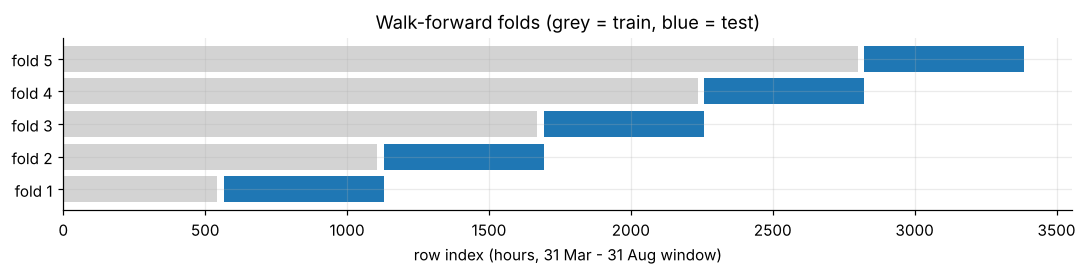

first test hour: 2025-03-31 17:00:00 | last: 2025-08-31 20:00:00 | test rows (h=3): 2820
                         MAE   RMSE    R2
1 Persistence           6.18  12.33  0.87
  Same hour yesterday  17.35  36.27 -0.10
2 Persistence           9.65  18.80  0.71
  Same hour yesterday  17.91  36.95 -0.14
3 Persistence          12.07  23.45  0.54
  Same hour yesterday  18.49  37.64 -0.18


In [9]:
def metrics(y, p): return dict(MAE=mean_absolute_error(y, p), RMSE=np.sqrt(mean_squared_error(y, p)), R2=r2_score(y, p))
tss = TimeSeriesSplit(n_splits=5, gap=24)
fig, ax = plt.subplots(figsize=(10, 2.6))
for k, (tr, te) in enumerate(tss.split(d3)):
    ax.barh(k, len(tr), left=0, color="lightgrey"); ax.barh(k, len(te), left=tr[-1] + 25, color="tab:blue")
ax.set_yticks(range(5)); ax.set_yticklabels([f"fold {k+1}" for k in range(5)]); ax.set_xlabel("row index (hours, 31 Mar - 31 Aug window)"); ax.set_title("Walk-forward folds (grey = train, blue = test)")
plt.tight_layout(); plt.show()
te_idx = np.concatenate([te for _, te in tss.split(d3)])
print("first test hour:", d3.index[te_idx[0]], "| last:", d3.index[te_idx[-1]], "| test rows (h=3):", len(te_idx))
base = {}
for h in (1, 2, 3):
    _, dh = hourly_frame(h); ti = np.concatenate([te for _, te in TimeSeriesSplit(5, gap=24).split(dh)]); y = np.exp(dh.y.iloc[ti])
    base[h] = {"Persistence": metrics(y, np.exp(dh.pm_lag0.iloc[ti])), "Same hour yesterday": metrics(y, np.exp(dh.pm_lag24.iloc[ti]))}
print(pd.concat({h: pd.DataFrame(v).T for h, v in base.items()}).round(2))

> **Observation:** The five folds cover 31 March to 31 August (2,820 test hours at the 3-hour horizon). Persistence is strong: MAE 6.18, 9.65 and 12.07 µg/m³ at 1, 2 and 3 hours (R² = 0.87, 0.71, 0.54). Repeating yesterday's value for the same hour is much worse (MAE 17–18, negative R²), so the daily cycle alone is not enough. Every model has to beat the persistence row to be worth using.

## 6. Models (Lab 10 Q9+, Assignment 6)
* **Ridge regression** (linear model with scaling in a `Pipeline`; penalty chosen by internal cross-validation) — models the log level directly.
* **Decision tree**, **Random forest**, **Gradient boosting** — the Lab 10 tree models, plus boosting.

**Two ways to set the target.** (i) *level*: predict ln PM(t+h). (ii) *change*: predict ln PM(t+h) − ln PM(t) and add it back to the current value. Trees can never output more than the largest value they saw in training, so in the level form they fail whenever PM2.5 reaches new highs; the change form removes that problem. We use the change form for the tree models (decided before looking at test scores) and show the level form below for comparison.

First, the Lab 10 style check of tree depth (3-hour horizon, set D, change target), using walk-forward error rather than one split:

 max_depth  test MAE
         2     11.91
         3     11.77
         4     11.63
         6     11.73
         8     11.81
        12     11.84
        20     11.84


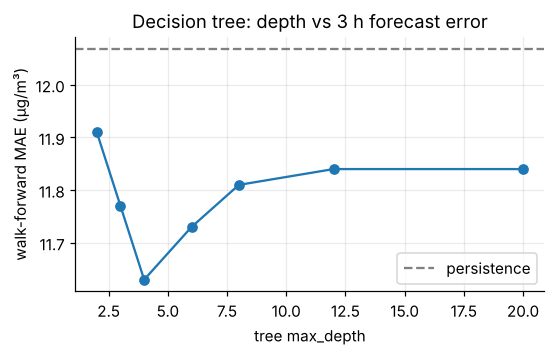

In [10]:
def walk_forward(d, cols, model_fn, delta=False, gap=24, n_splits=5):
    pred = pd.Series(np.nan, index=d.index); off = d["pm_lag0"] if delta else pd.Series(0.0, index=d.index)
    for tr, te in TimeSeriesSplit(n_splits, gap=gap).split(d):
        m = model_fn().fit(d.iloc[tr][cols].values, (d.iloc[tr].y - off.iloc[tr]).values)
        pred.iloc[te] = m.predict(d.iloc[te][cols].values) + off.iloc[te].values
    return pred

ti = np.concatenate([te for _, te in TimeSeriesSplit(5, gap=24).split(d3)]); y3 = np.exp(d3.y.iloc[ti])
rows = []
for depth in (2, 3, 4, 6, 8, 12, 20):
    p = walk_forward(d3, FEATSETS["D: A + NO2 + weather"], lambda: DecisionTreeRegressor(max_depth=depth, min_samples_leaf=20, random_state=SEED), delta=True)
    tr_p = {}
    rows.append((depth, mean_absolute_error(y3, np.exp(p.iloc[ti]))))
dt = pd.DataFrame(rows, columns=["max_depth", "test MAE"]).round(2); print(dt.to_string(index=False))
fig, ax = plt.subplots(figsize=(5.5, 3)); ax.plot(dt.max_depth, dt["test MAE"], "o-"); ax.axhline(base[3]["Persistence"]["MAE"], color="grey", ls="--", label="persistence")
ax.set_xlabel("tree max_depth"); ax.set_ylabel("walk-forward MAE (µg/m³)"); ax.set_title("Decision tree: depth vs 3 h forecast error"); ax.legend(); plt.show()

> **Observation:** A single decision tree on changes in ln PM2.5 improves from depth 2 (MAE 11.91) to a best depth of 4 (11.63) and then gets slightly worse for deeper trees (11.84 at depth 12–20) as it starts to fit noise. Even the best single tree is only about 4% better than persistence (12.07), so the gain is small; ensembles are used below.

### 6.1 Main experiment: feature sets A–D × models × horizons

In [11]:
def make_models():
    return {"Ridge (level)":        (lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 16))), False),
            "Random forest (change)": (lambda: RandomForestRegressor(150, min_samples_leaf=3, max_features=.5, n_jobs=-1, random_state=SEED), True),
            "Gradient boosting (change)": (lambda: HistGradientBoostingRegressor(max_iter=200, learning_rate=.05, max_leaf_nodes=15, l2_regularization=1., random_state=SEED), True)}
res, PRED, TEST = {}, {}, {}
for h in (1, 2, 3):
    _, dh = hourly_frame(h); ti = np.concatenate([te for _, te in TimeSeriesSplit(5, gap=24).split(dh)]); y = np.exp(dh.y.iloc[ti])
    TEST[h] = dict(idx=dh.index[ti], y=y, persist=np.exp(dh.pm_lag0.iloc[ti]))
    res[(h, "Persistence", "-")] = metrics(y, TEST[h]["persist"])
    for sname, cols in FEATSETS.items():
        for mname, (fn, dl) in make_models().items():
            p = np.exp(walk_forward(dh, cols, fn, delta=dl).iloc[ti]); PRED[(h, sname, mname)] = p; res[(h, mname, sname[0])] = metrics(y, p)
R = pd.DataFrame(res).T; R.index.names = ["h", "model", "set"]
tab = R["MAE"].unstack("h").round(2); print("MAE (µg/m³) by horizon\n", tab)
print("\nR² at 3 h\n", R["R2"].xs(3, level="h").round(3))

MAE (µg/m³) by horizon
 h                                  1      2      3
model                      set                    
Gradient boosting (change) A    6.23   9.30  11.35
                           B    6.31   9.32  11.28
                           C    6.24   9.14  10.71
                           D    6.22   9.05  10.89
Persistence                -    6.18   9.65  12.07
Random forest (change)     A    5.92   8.99  10.78
                           B    5.94   8.91  10.82
                           C    5.88   8.69  10.39
                           D    5.84   8.60  10.37
Ridge (level)              A    6.14   9.35  11.24
                           B    6.15   9.26  11.02
                           C    6.52  10.08  11.69
                           D    6.44   9.64  11.41

R² at 3 h
 model                       set
Persistence                 -      0.544
Ridge (level)               A      0.580
Random forest (change)      A      0.653
Gradient boosting (change)  A      0.624
Rid

> **Observation:** Best result: the random forest on changes, with weather (sets C and D), reaches MAE 5.84 / 8.60 / 10.37 µg/m³ at 1 / 2 / 3 hours, i.e. about 5%, 11% and 14% below persistence (6.18 / 9.65 / 12.07), and R² at 3 hours rises from 0.544 to 0.69. (1) *PM history alone* (set A) already helps a little (3 h: 10.78). (2) *NO2 adds nothing*: A → B changes the 3-hour MAE from 10.78 to 10.82 for the forest and from 11.35 to 11.28 for boosting. (3) *Weather helps at 2–3 hours*: A → C lowers the forest's MAE from 8.99 to 8.69 (2 h) and from 10.78 to 10.39 (3 h), but not at 1 hour (5.92 → 5.88). (4) *Ridge does not benefit from weather* (3 h: 11.24 → 11.69), which suggests the weather effects are non-linear or depend on the season. (5) Gradient boosting lies between Ridge and the forest.

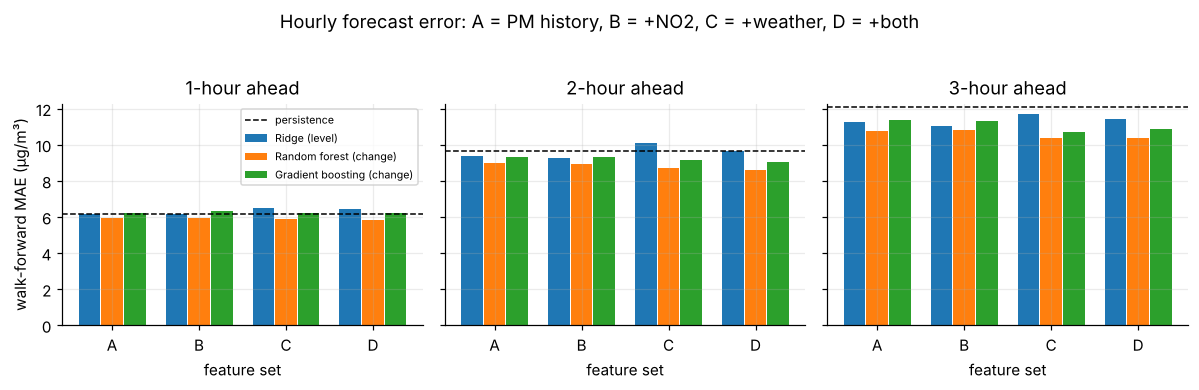

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
for a, h in zip(ax, (1, 2, 3)):
    for j, (mname, col) in enumerate(zip(make_models(), ["tab:blue", "tab:orange", "tab:green"])):
        vals = [R.loc[(h, mname, s[0]), "MAE"] for s in FEATSETS]; a.bar(np.arange(4) + (j - 1) * .26, vals, .25, label=mname, color=col)
    a.axhline(R.loc[(h, "Persistence", "-"), "MAE"], color="k", ls="--", lw=1, label="persistence"); a.set_xticks(range(4)); a.set_xticklabels(list("ABCD"))
    a.set_title(f"{h}-hour ahead"); a.set_xlabel("feature set")
ax[0].set_ylabel("walk-forward MAE (µg/m³)"); ax[0].legend(fontsize=7); plt.suptitle("Hourly forecast error: A = PM history, B = +NO2, C = +weather, D = +both", y=1.03); plt.tight_layout(); plt.show()

> **Observation:** The bars show the same story: the dashed persistence line is hard to beat at 1 hour (all bars are close to it), and the gap opens up with the horizon, with the forest/boosting models using weather (C, D) lowest at 3 hours.

In [13]:
# Level vs change target for the random forest (3 h, set A)
dh = d3; ti = np.concatenate([te for _, te in TimeSeriesSplit(5, gap=24).split(dh)]); y = np.exp(dh.y.iloc[ti])
rf_fn = lambda: RandomForestRegressor(150, min_samples_leaf=3, max_features=.5, n_jobs=-1, random_state=SEED)
for dl in (False, True):
    p = walk_forward(dh, FEATSETS["A: PM history"], rf_fn, delta=dl); m = metrics(y, np.exp(p.iloc[ti]))
    print("RF, set A, target =", "change" if dl else "level ", "| MAE %.2f  RMSE %.2f  R2 %.3f" % (m["MAE"], m["RMSE"], m["R2"]))
hi = y > 120; print("test hours above 120 µg/m³:", int(hi.sum()))
for dl in (False, True):
    p = np.exp(walk_forward(dh, FEATSETS["A: PM history"], rf_fn, delta=dl).iloc[ti]); print("  target", "change" if dl else "level ", "MAE on those hours: %.1f" % mean_absolute_error(y[hi], p[hi]))
print("  persistence MAE on those hours: %.1f" % mean_absolute_error(y[hi], np.exp(dh.pm_lag0.iloc[ti])[hi]))

RF, set A, target = level  | MAE 11.47  RMSE 24.95  R2 0.483


RF, set A, target = change | MAE 10.78  RMSE 20.44  R2 0.653
test hours above 120 µg/m³: 48


  target level  MAE on those hours: 117.7


  target change MAE on those hours: 84.2
  persistence MAE on those hours: 74.9


> **Observation:** The level formulation is worse than the change formulation for the forest (3 h MAE 11.47 vs 10.78, R² 0.48 vs 0.65), and the difference is concentrated in the high-pollution hours: on the 48 test hours above 120 µg/m³ the level model's MAE is 117.7 against 84.2 for the change model. This is the tree extrapolation limit that Yashvi also found in Model A (trees cannot predict above the highest training value). Even the change model is still worse than persistence on those extreme hours (74.9).

### 6.2 Is the improvement real? Paired day-block bootstrap
A lower MAE on one test set can be luck, especially because neighbouring hours are strongly dependent. We resample whole **days** (2,000 times) and report the 95% interval for the *difference* in MAE between two models on the same hours. An interval that excludes 0 means the difference is unlikely to be chance. (No correction for multiple comparisons.)

In [14]:
def day_boot(ea, eb, idx, B=2000, seed=SEED):
    rng = np.random.default_rng(seed); df = pd.DataFrame({"d": (np.abs(ea) - np.abs(eb)).values, "day": pd.DatetimeIndex(idx).normalize()})
    g = df.groupby("day").d.agg(["sum", "count"]); s, c = g["sum"].values, g["count"].values
    bs = [s[i].sum() / c[i].sum() for i in (rng.integers(0, len(g), len(g)) for _ in range(B))]
    return np.mean(np.abs(ea) - np.abs(eb)), np.percentile(bs, 2.5), np.percentile(bs, 97.5)
mn = "Random forest (change)"; rows = []
for h in (1, 2, 3):
    ix, y, pp = TEST[h]["idx"], TEST[h]["y"], TEST[h]["persist"]; e = {s[0]: PRED[(h, s, mn)] - y for s in FEATSETS}; ep = pp - y
    for lab, a, b in (("PM history vs persistence (A vs P)", e["A"], ep), ("+NO2 (B vs A)", e["B"], e["A"]), ("+weather (C vs A)", e["C"], e["A"]),
                      ("+weather on top of NO2 (D vs B)", e["D"], e["B"]), ("best set vs persistence (D vs P)", e["D"], ep)):
        m, lo, hi_ = day_boot(a, b, ix); rows.append((h, lab, round(m, 2), f"[{lo:+.2f}, {hi_:+.2f}]", "yes" if (lo > 0 or hi_ < 0) else "no"))
print(pd.DataFrame(rows, columns=["horizon (h)", "ΔMAE (neg = first is better)", "ΔMAE", "95% CI", "excludes 0?"]).to_string(index=False))

 horizon (h)       ΔMAE (neg = first is better)  ΔMAE         95% CI excludes 0?
           1 PM history vs persistence (A vs P) -0.25 [-0.48, -0.04]         yes
           1                      +NO2 (B vs A)  0.02 [-0.11, +0.15]          no
           1                  +weather (C vs A) -0.04 [-0.18, +0.08]          no
           1    +weather on top of NO2 (D vs B) -0.09 [-0.19, +0.00]          no
           1   best set vs persistence (D vs P) -0.33 [-0.56, -0.10]         yes
           2 PM history vs persistence (A vs P) -0.66 [-1.11, -0.21]         yes
           2                      +NO2 (B vs A) -0.07 [-0.27, +0.12]          no
           2                  +weather (C vs A) -0.30 [-0.50, -0.12]         yes
           2    +weather on top of NO2 (D vs B) -0.32 [-0.49, -0.16]         yes
           2   best set vs persistence (D vs P) -1.05 [-1.53, -0.58]         yes
           3 PM history vs persistence (A vs P) -1.29 [-1.99, -0.61]         yes
           3                

> **Observation:** Reading the table: a negative ΔMAE means the first model is better, and 'yes' means the interval excludes zero. (i) PM-history models beat persistence at all three horizons. (ii) **Adding NO2 never helps** (intervals include 0 at every horizon). (iii) **Adding weather helps significantly at 2 and 3 hours** (3 h: −0.39 [−0.65, −0.17] µg/m³ over PM history; −0.45 [−0.67, −0.26] on top of NO2) but not at 1 hour. (iv) The best set beats persistence at every horizon (3 h: −1.70 [−2.46, −0.99]). The improvements are modest in absolute terms (about 0.4 µg/m³ for weather) and have not been corrected for the number of comparisons.

### 6.3 Where does the model fail? Error by concentration level and by month (3 h ahead)

MAE (µg/m³) by observed concentration regime
         n hours  Persistence  RF set A  RF set C
y                                               
<30        1230          6.9       6.6       6.7
30-60       983         12.4      10.0       9.5
60-120      559         17.5      15.0      14.3
>120         48         74.9      84.2      77.3

MAE by month
      Persistence  RF set A  RF set C
Mar         13.1      11.8      11.7
Apr         19.6      16.1      15.3
May         20.1      17.3      16.5
Jun         10.4      10.3       9.9
Jul          7.4       7.1       7.3
Aug          5.3       5.1       4.8


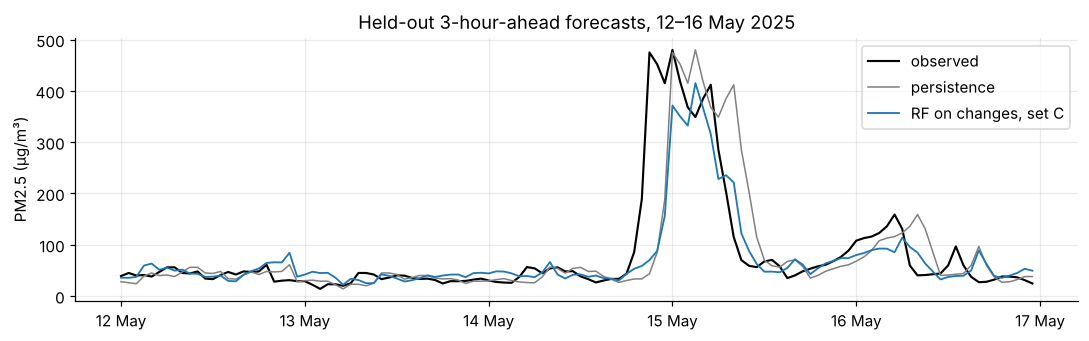

In [15]:
ix, y, pp = TEST[3]["idx"], TEST[3]["y"], TEST[3]["persist"]
pa, pc = PRED[(3, "A: PM history", mn)], PRED[(3, "C: A + weather", mn)]
reg = pd.cut(y, [0, 30, 60, 120, 1e5], labels=["<30", "30-60", "60-120", ">120"])
tab = pd.DataFrame({"n hours": reg.value_counts().sort_index(), "Persistence": [mean_absolute_error(y[reg == k], pp[reg == k]) for k in reg.cat.categories],
                    "RF set A": [mean_absolute_error(y[reg == k], pa[reg == k]) for k in reg.cat.categories], "RF set C": [mean_absolute_error(y[reg == k], pc[reg == k]) for k in reg.cat.categories]}).round(1)
print("MAE (µg/m³) by observed concentration regime\n", tab)
mo = pd.DataFrame({"Persistence": [mean_absolute_error(y[ix.month == m], pp[ix.month == m]) for m in range(3, 9)], "RF set A": [mean_absolute_error(y[ix.month == m], pa[ix.month == m]) for m in range(3, 9)],
                   "RF set C": [mean_absolute_error(y[ix.month == m], pc[ix.month == m]) for m in range(3, 9)]}, index=["Mar", "Apr", "May", "Jun", "Jul", "Aug"]).round(1); print("\nMAE by month\n", mo)
sel = (ix >= "2025-05-12") & (ix < "2025-05-17"); fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(ix[sel], y[sel], "k", lw=1.4, label="observed"); ax.plot(ix[sel], pp[sel], color="grey", lw=1, label="persistence"); ax.plot(ix[sel], pc[sel], color="tab:blue", lw=1.2, label="RF on changes, set C")
ax.set_title("Held-out 3-hour-ahead forecasts, 12–16 May 2025"); ax.set_ylabel("PM2.5 (µg/m³)"); ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b")); ax.legend(); plt.tight_layout(); plt.show()

> **Observation:** Errors grow with the concentration level. Compared with persistence, the weather model gives its biggest gains in the 30–60 and 60–120 µg/m³ ranges (12.4 → 9.5 and 17.5 → 14.3), and is similar below 30. For the rare very high hours (>120 µg/m³, only 48 test hours) neither model beats persistence (74.9 vs 84.2 for set A and 77.3 for set C), so extreme episodes remain unpredictable. By month, the gains are concentrated in April (19.6 → 15.3) and May (20.1 → 16.5), the most variable pre-monsoon months, and are small elsewhere. The May example shows the models following the persistence curve closely and reacting a little earlier to rises and falls.

### 6.4 Which features does the model use? (permutation importance, last fold, 3 h ahead)

last fold covers 2025-08-04 to 2025-08-31
pm_roll3     0.0757
pm_lag0      0.0587
hr_cos       0.0199
wind_u       0.0196
pm_roll24    0.0165
pm_diff3     0.0128
pm_lag1      0.0084
wind_v       0.0069
pm_lag6      0.0052
rh           0.0051
dtype: float64


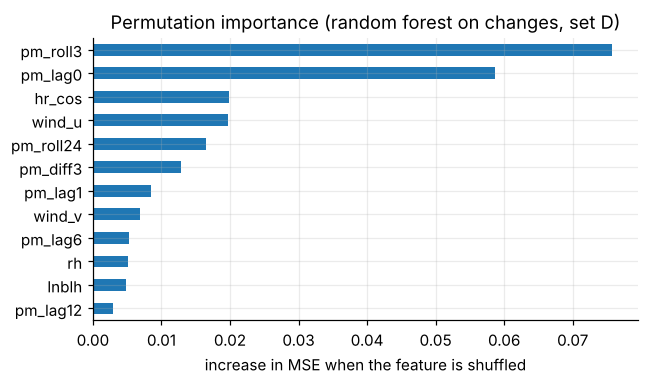

In [16]:
cols = FEATSETS["D: A + NO2 + weather"]; tr, te = list(TimeSeriesSplit(5, gap=24).split(d3))[-1]
off = d3.pm_lag0
rf = RandomForestRegressor(200, min_samples_leaf=3, max_features=.5, n_jobs=-1, random_state=SEED).fit(d3.iloc[tr][cols], (d3.y - off).iloc[tr])
pi = permutation_importance(rf, d3.iloc[te][cols], (d3.y - off).iloc[te], n_repeats=20, random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=cols).sort_values(ascending=False)
print("last fold covers", d3.index[te[0]].date(), "to", d3.index[te[-1]].date()); print(imp.head(10).round(4))
fig, ax = plt.subplots(figsize=(6, 3.6)); imp.head(12)[::-1].plot.barh(ax=ax, color="tab:blue"); ax.set_title("Permutation importance (random forest on changes, set D)"); ax.set_xlabel("increase in MSE when the feature is shuffled"); plt.tight_layout(); plt.show()

> **Observation:** In the random forest trained on changes, the most important inputs in the last fold are the recent level of PM2.5 (3-hour mean, current value), then the hour of day (hr_cos), the east-west wind component and the 24-hour mean. Two cautions: the last fold covers only 4–31 August, a clean monsoon month, so the ranking of weather variables is specific to that period; and permutation importance shows what the model *uses*, not what *causes* PM2.5.

## 7. Day-ahead forecasting with fire features
Weather is not available after 31 Aug, but fire counts are available for the full season, so the day-ahead problem (daily mean PM2.5 of day *d+1* from information up to day *d*) is where fires can be tested. Fire detections: only presumed vegetation fires (`type == 0`) are used, and each detection is assigned to its **India-local day** (UTC + 5.5 h) — this reproduces Khushi's `fires_daily.csv` exactly. A daily PM2.5 mean is used only if at least 12 hours of that day are available.

In [17]:
f = pd.read_csv(RAW / "fires" / "firms_noaa20_2025_mar_nov.csv")
tt = pd.to_datetime(f.acq_date) + pd.to_timedelta((f.acq_time // 100) * 60 + f.acq_time % 100, unit="m")
f["date"] = (tt + pd.Timedelta(hours=5, minutes=30)).dt.normalize(); f = f[f.type == 0]
f["nw"] = (f.latitude > 28.53) & (f.longitude < 77.19)
days = pd.date_range("2025-03-01", "2025-11-30"); g = f.groupby("date")
D = pd.DataFrame({"pm25": pm.resample("D").mean().where(pm.resample("D").count() >= 12), "no2": no2.resample("D").mean().where(no2.resample("D").count() >= 12)}).loc[days]
D["fire_count"] = g.size().reindex(days).fillna(0); D["fire_nw"] = f[f.nw].groupby("date").size().reindex(days).fillna(0); D["fire_frp"] = g.frp.sum().reindex(days).fillna(0)
tm = pd.read_csv(ROOT / "data" / "processed" / "fires_daily.csv", parse_dates=["date"]).set_index("date") if (ROOT / "data" / "processed" / "fires_daily.csv").exists() else None
if tm is not None: print("matches Khushi's fires_daily.csv fire_count for all days:", bool((tm.fire_count.reindex(days).values == D.fire_count.values).all()))
print("days:", len(D), "| valid PM2.5 days:", int(D.pm25.notna().sum()), "| zero-fire days:", int((D.fire_count == 0).sum()))
Di = D.copy(); Di["pm25"] = Di.pm25.interpolate("time", limit=2, limit_area="inside"); Di["no2"] = Di.no2.interpolate("time", limit=2, limit_area="inside")
G = pd.DataFrame(index=days); lp, ln_ = np.log(Di.pm25), np.log(Di.no2)
for L in (0, 1, 2, 6): G[f"pm_lag{L}"] = lp.shift(L)
G["pm_roll3"] = lp.rolling(3, min_periods=2).mean(); G["pm_roll7"] = lp.rolling(7, min_periods=4).mean()
G["no2_lag0"] = ln_; G["no2_roll3"] = ln_.rolling(3, min_periods=2).mean()
G["fire0"] = np.log1p(D.fire_count); G["fire_roll3"] = np.log1p(D.fire_count.rolling(3).mean()); G["fire_roll7"] = np.log1p(D.fire_count.rolling(7).mean())
G["fire_nw0"] = np.log1p(D.fire_nw); G["fire_frp0"] = np.log1p(D.fire_frp)
DP = [c for c in G if c.startswith("pm_")]; DN = ["no2_lag0", "no2_roll3"]; DF = [c for c in G if c.startswith("fire")]
DSETS = {"A: PM history": DP, "B: A + NO2": DP + DN, "C: A + NO2 + fires": DP + DN + DF}
dd = pd.concat([G, np.log(D.pm25.shift(-1)).rename("y")], axis=1).dropna(); print("daily modelling rows:", len(dd), "from", dd.index[0].date(), "to", dd.index[-1].date())

matches Khushi's fires_daily.csv fire_count for all days: True
days: 275 | valid PM2.5 days: 265 | zero-fire days: 44
daily modelling rows: 254 from 2025-03-07 to 2025-11-29


> **Observation:** The fire table rebuilt from the raw FIRMS file (vegetation fires only, India-local day) matches Khushi's `fires_daily.csv` on all 275 days, with 44 zero-fire days. There are 265 days with a valid PM2.5 mean (at least 12 hours observed) and 254 usable rows after the lag features (starting 7 March) and the next-day target are applied.

In [18]:
ti = np.concatenate([te for _, te in TimeSeriesSplit(5, gap=1).split(dd)]); yd = np.exp(dd.y.iloc[ti]); pers = np.exp(dd.pm_lag0.iloc[ti])
resd = {"Persistence": metrics(yd, pers), "7-day mean": metrics(yd, np.exp(dd.pm_roll7.iloc[ti]))}; PD = {}
def mk_daily(): return {"Ridge (level)": (lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 16))), False),
                        "RF (level)": (lambda: RandomForestRegressor(150, min_samples_leaf=3, max_features=.5, n_jobs=-1, random_state=SEED), False),
                        "RF (change)": (lambda: RandomForestRegressor(150, min_samples_leaf=3, max_features=.5, n_jobs=-1, random_state=SEED), True),
                        "GBM (change)": (lambda: HistGradientBoostingRegressor(max_iter=200, learning_rate=.05, max_leaf_nodes=15, l2_regularization=1., random_state=SEED), True)}
for sname, cols in DSETS.items():
    for mname, (fn, dl) in mk_daily().items():
        p = np.exp(walk_forward(dd, cols, fn, delta=dl, gap=1).iloc[ti]); PD[(sname, mname)] = p; resd[f"{sname[0]} | {mname}"] = metrics(yd, p)
tabd = pd.DataFrame(resd).T.round(2); print(f"Walk-forward day-ahead, {len(ti)} test days from {dd.index[ti[0]].date()}\n", tabd)

Walk-forward day-ahead, 210 test days from 2025-04-25
                      MAE   RMSE    R2
Persistence        16.30  36.19  0.65
7-day mean         17.45  36.79  0.64
A | Ridge (level)  16.91  34.36  0.69
A | RF (level)     29.10  57.92  0.11
A | RF (change)    19.61  39.52  0.58
A | GBM (change)   19.05  39.08  0.59
B | Ridge (level)  16.90  34.30  0.69
B | RF (level)     30.17  59.08  0.07
B | RF (change)    19.59  39.11  0.59
B | GBM (change)   19.53  38.85  0.60
C | Ridge (level)  20.92  39.95  0.58
C | RF (level)     29.38  58.57  0.09
C | RF (change)    17.99  37.68  0.62
C | GBM (change)   18.93  38.73  0.60


> **Observation:** With 210 walk-forward test days, persistence has MAE 16.30 µg/m³ (R² 0.65). Ridge on PM history has a slightly higher R² (0.69) and lower RMSE (34.4 vs 36.2) but a higher MAE (16.9), so it is not clearly better. Tree ensembles in level form fail (RF MAE 29.1, R² 0.11), and with the change target they reach 18–20, still above persistence. **Fire features do not improve day-ahead forecasts**: Ridge gets worse with them (16.9 → 20.9) and the forest on changes improves only to 17.99, still worse than persistence. This agrees with Yashvi's Model A, where persistence also had the lowest error (MAE 16.22, with different fold sizes), and shows that the fire signal she found in Model C is mostly a seasonal marker that PM2.5 history already carries.

Rolling origin, 60 days (1 Oct - 30 Nov)
                      MAE   RMSE    R2
Persistence        31.93  58.93  0.44
A | Ridge (level)  28.53  54.78  0.51
A | GBM (change)   31.24  57.08  0.47
A | RF (change)    34.58  60.65  0.40
B | Ridge (level)  28.39  54.74  0.51
B | GBM (change)   35.50  61.04  0.39
B | RF (change)    35.00  60.43  0.41
C | Ridge (level)  31.44  58.29  0.45
C | GBM (change)   36.41  61.99  0.37
C | RF (change)    34.92  60.63  0.40
        model       comparison  ΔMAE          95% CI excludes 0?
Ridge (level)    +NO2 (B vs A) -0.15  [-0.50, +0.18]          no
Ridge (level)  +fires (C vs B)  3.05  [-0.39, +6.69]          no
Ridge (level) C vs persistence -0.49 [-10.14, +7.65]          no
  RF (change)    +NO2 (B vs A)  0.43  [-0.87, +1.74]          no
  RF (change)  +fires (C vs B) -0.08  [-1.84, +1.84]          no
  RF (change) C vs persistence  2.99  [-2.72, +8.33]          no
 GBM (change)    +NO2 (B vs A)  4.26  [+1.10, +7.97]         yes
 GBM (change)  +fire

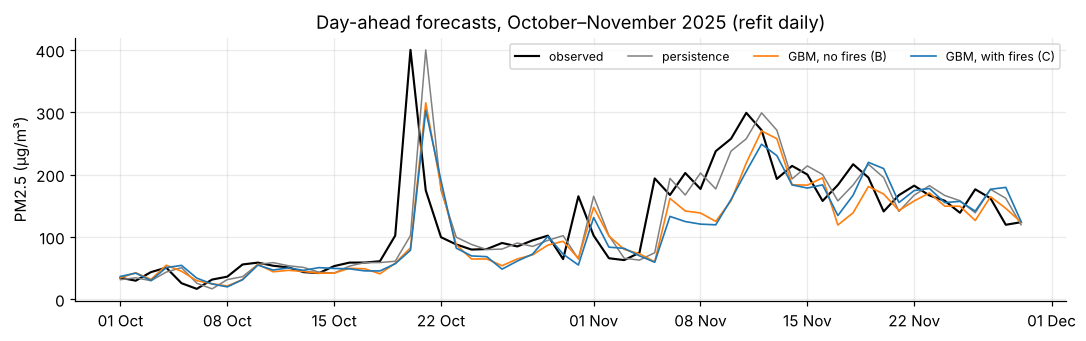

In [19]:
# Hardest part of the season: rolling origin over Oct-Nov, refit every day (expanding window)
ro_idx = dd.index[dd.index >= "2025-10-01"]; yro = np.exp(dd.loc[ro_idx, "y"]); ro = {}
for sname in DSETS:
    for mname in ("Ridge (level)", "GBM (change)", "RF (change)"):
        fn, dl = mk_daily()[mname]; pr = []
        for t in ro_idx:
            tr = dd.loc[:t - pd.Timedelta(days=2)]; off_tr = tr.pm_lag0.values if dl else 0.0; off_te = dd.loc[t, "pm_lag0"] if dl else 0.0
            pr.append(fn().fit(tr[DSETS[sname]].values, tr.y.values - off_tr).predict(dd.loc[[t], DSETS[sname]].values)[0] + off_te)
        ro[(sname, mname)] = pd.Series(np.exp(pr), index=ro_idx)
pr_ro = np.exp(dd.loc[ro_idx, "pm_lag0"]); out = {"Persistence": metrics(yro, pr_ro)}; out.update({f"{k[0][0]} | {k[1]}": metrics(yro, v) for k, v in ro.items()})
print(f"Rolling origin, {len(ro_idx)} days (1 Oct - 30 Nov)\n", pd.DataFrame(out).T.round(2))
rows = []
for mname in ("Ridge (level)", "RF (change)", "GBM (change)"):
    e = {s[0]: ro[(s, mname)] - yro for s in DSETS}
    for lab, a, b in (("+NO2 (B vs A)", e["B"], e["A"]), ("+fires (C vs B)", e["C"], e["B"]), ("C vs persistence", e["C"], pr_ro - yro)):
        m, lo, hi_ = day_boot(a, b, ro_idx); rows.append((mname, lab, round(m, 2), f"[{lo:+.2f}, {hi_:+.2f}]", "yes" if (lo > 0 or hi_ < 0) else "no"))
print(pd.DataFrame(rows, columns=["model", "comparison", "ΔMAE", "95% CI", "excludes 0?"]).to_string(index=False))
fig, ax = plt.subplots(figsize=(10, 3.2)); ax.plot(ro_idx, yro, "k", lw=1.4, label="observed"); ax.plot(ro_idx, pr_ro, color="grey", lw=1, label="persistence")
ax.plot(ro_idx, ro[("B: A + NO2", "GBM (change)")], color="tab:orange", lw=1.1, label="GBM, no fires (B)"); ax.plot(ro_idx, ro[("C: A + NO2 + fires", "GBM (change)")], color="tab:blue", lw=1.1, label="GBM, with fires (C)")
ax.set_title("Day-ahead forecasts, October–November 2025 (refit daily)"); ax.set_ylabel("PM2.5 (µg/m³)"); ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b")); ax.legend(ncol=4, fontsize=8); plt.tight_layout(); plt.show()

> **Observation:** October–November is much harder (persistence MAE 31.93, R² 0.44) because of the Diwali episode and the November plateau. Ridge on PM history is best (MAE 28.53, R² 0.51 vs 0.44), but this is a 60-day test with one extreme episode and we did not test it against persistence. Adding NO2 (B vs A) changes nothing for Ridge and the forest and makes boosting significantly worse (+4.26 [+1.10, +7.97]). **Adding fires (C vs B) has no significant effect for any model** (all intervals include 0; Ridge is +3.05 [−0.39, +6.69], i.e. if anything worse), and set C is not significantly better than persistence.

## 8. Classification: will the 60 µg/m³ standard be exceeded? (Lab 11)
We turn the forecast into a yes/no question: **exceedance = PM2.5 above 60 µg/m³**, predicted (a) for tomorrow's daily mean and (b) 3 hours ahead. Same walk-forward test rows as before. As in Lab 11 we first build a *lazy baseline* (always "no exceedance") and also the *persistence rule* ("same class as now"), then Logistic regression, Decision tree and Random forest. Because exceedance is not rare in this data (about a third of days), accuracy is informative, but we also report precision, recall, F1 and ROC AUC.

In [20]:
def cls_scores(y, p, s=None):
    d = dict(accuracy=accuracy_score(y, p), precision=precision_score(y, p, zero_division=0), recall=recall_score(y, p), F1=f1_score(y, p))
    if s is not None: d["ROC AUC"] = roc_auc_score(y, s)
    return d
def cls_models(): return {"Logistic": make_pipeline(StandardScaler(), LogisticRegression(C=.5, max_iter=2000, random_state=SEED)),
                          "Decision tree": DecisionTreeClassifier(max_depth=4, min_samples_leaf=10, random_state=SEED),
                          "Random forest": RandomForestClassifier(200, min_samples_leaf=3, max_features=.5, n_jobs=-1, random_state=SEED)}
def run_cls(d, cols, gap, today="pm_lag0", thr=np.log(60)):
    y = (d.y > thr).astype(int); ti = np.concatenate([te for _, te in TimeSeriesSplit(5, gap=gap).split(d)]); P, S = {}, {}
    P["Lazy (always no)"] = np.zeros(len(ti), int); P["Persistence rule"] = (d[today].iloc[ti] > thr).astype(int).values; S["Persistence rule"] = d[today].iloc[ti].values
    for mname in cls_models():
        p = np.zeros(len(ti), int); s = np.zeros(len(ti))
        for tr, te in TimeSeriesSplit(5, gap=gap).split(d):
            m = cls_models()[mname].fit(d.iloc[tr][cols].values, y.iloc[tr]); k = np.searchsorted(ti, te)
            p[k] = m.predict(d.iloc[te][cols].values); s[k] = m.predict_proba(d.iloc[te][cols].values)[:, 1]
        P[mname], S[mname] = p, s
    yt = y.iloc[ti].values; tab = pd.DataFrame({k: cls_scores(yt, P[k], S.get(k)) for k in P}).T.round(3); return tab, yt, P
tab_d, yt_d, P_d = run_cls(dd, DSETS["A: PM history"], gap=1)
print(f"DAILY next-day exceedance: {len(yt_d)} test days, {yt_d.mean():.0%} exceed 60\n", tab_d)
tab_h, yt_h, P_h = run_cls(d3, FEATSETS["A: PM history"], gap=24)
print(f"\nHOURLY 3-h-ahead exceedance: {len(yt_h)} test hours, {yt_h.mean():.0%} exceed 60\n", tab_h)

DAILY next-day exceedance: 210 test days, 31% exceed 60
                   accuracy  precision  recall     F1  ROC AUC
Lazy (always no)     0.686      0.000   0.000  0.000      NaN
Persistence rule     0.900      0.846   0.833  0.840    0.957
Logistic             0.900      0.846   0.833  0.840    0.955
Decision tree        0.867      0.764   0.833  0.797    0.856
Random forest        0.676      0.469   0.227  0.306    0.852



HOURLY 3-h-ahead exceedance: 2820 test hours, 22% exceed 60
                   accuracy  precision  recall     F1  ROC AUC
Lazy (always no)     0.785      0.000   0.000  0.000      NaN
Persistence rule     0.888      0.743   0.736  0.739    0.932
Logistic             0.888      0.784   0.659  0.716    0.947
Decision tree        0.873      0.718   0.679  0.698    0.908
Random forest        0.893      0.774   0.707  0.739    0.940


> **Observation:** Daily: 31% of the 210 test days exceed 60 µg/m³, so the lazy 'never exceeds' model has 68.6% accuracy but recall 0, i.e. it never warns of a bad day. The persistence rule is already excellent (accuracy 0.900, precision 0.846, recall 0.833, F1 0.840, AUC 0.957) and Logistic regression on PM history ties it (same scores, AUC 0.955). The decision tree is slightly worse (F1 0.797) and the random forest fails (accuracy 0.676, recall 0.227, below even the lazy baseline) because trees trained on early, cleaner periods rarely see the high class. Hourly (3 h ahead, 22% exceed): the lazy model has accuracy 0.785; persistence gives 0.888 / F1 0.739; the forest matches it (0.893 / 0.739, AUC 0.940) and Logistic has the best AUC (0.947). No ML model is clearly better than the persistence rule.

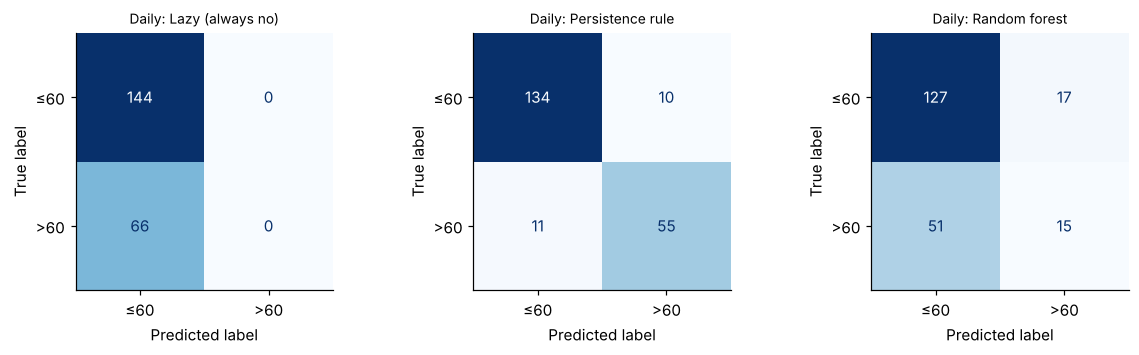

Logistic, daily: PM history only vs + NO2 + fires
    accuracy  precision  recall     F1  ROC AUC
A     0.900      0.846   0.833  0.840    0.955
C     0.867      0.744   0.879  0.806    0.904


In [21]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3.3))
for a, nm in zip(ax, ["Lazy (always no)", "Persistence rule", "Random forest"]):
    ConfusionMatrixDisplay(confusion_matrix(yt_d, P_d[nm]), display_labels=["≤60", ">60"]).plot(ax=a, colorbar=False, cmap="Blues"); a.set_title(f"Daily: {nm}", fontsize=9); a.grid(False)
plt.tight_layout(); plt.show()
# do NO2 / fires help classification? (daily, logistic regression, set A vs C)
ta, _, _ = run_cls(dd, DSETS["A: PM history"], gap=1); tc, _, _ = run_cls(dd, DSETS["C: A + NO2 + fires"], gap=1)
print("Logistic, daily: PM history only vs + NO2 + fires\n", pd.DataFrame({"A": ta.loc["Logistic"], "C": tc.loc["Logistic"]}).T)

> **Observation:** The confusion matrices show what the lazy baseline hides (all 66 exceedance days missed) and that the persistence rule and the random forest differ mainly in missed warnings. Adding NO2 and fires to the daily Logistic model does not help: accuracy falls from 0.900 to 0.867, F1 from 0.840 to 0.806 and AUC from 0.955 to 0.904 (recall rises to 0.879, but precision falls to 0.744, i.e. more false alarms).

## 9. Summary of decisions and results

| Decision | What we did | Why |
|---|---|---|
| Target | ln PM2.5 at t+h (h = 1–3 h) and next-day mean; scored on real (non-interpolated) readings | PM2.5 is right-skewed; interpolated values must not be the answer key |
| Validation | `TimeSeriesSplit(5)` walk-forward with a 24 h (hourly) / 1 day (daily) purge gap; same test rows for every model | no future data in training; fair comparison |
| Baselines | persistence, same-hour-yesterday, 7-day mean, lazy classifier | the scores every model has to beat |
| Tree models | predict the *change* from the current value | trees cannot predict above their training maximum |
| Feature sets | A history → B +NO2 → C +weather → D +both (hourly); A → B → C +fires (daily) | ablation: measures what each group adds |
| Significance | paired bootstrap over days (2,000 resamples) | hours within a day are strongly dependent |

**Key results**
1. PM2.5 is very persistent (autocorrelation 0.97 at 1 h). Persistence is a strong baseline: MAE 6.2 / 9.7 / 12.1 µg/m³ at 1 / 2 / 3 hours.
2. The best model (random forest on changes with weather) is about 5% / 11% / 14% better than persistence at 1 / 2 / 3 hours; the gain from weather alone is about 0.3–0.4 µg/m³ at 2–3 hours, statistically significant but small, and not present at 1 hour.
3. NO2 does not improve any forecast, even though it is the best short-lead correlate.
4. Fire counts do not improve day-ahead forecasts (neither in the whole season nor in October–November); fire counts mostly mark the season.
5. Day-ahead models do not beat persistence in MAE; Ridge gives a slightly higher R² and lower RMSE.
6. Exceedance of 60 µg/m³ is predicted well (AUC ≈ 0.95), but the persistence rule is as good as any model.
7. Very high hours (> 120 µg/m³) are not predicted better than by persistence.

**Limitations.** (i) Weather ends on 31 Aug, so no weather result covers October–November; extending the download to 30 Nov and re-running this notebook is the first thing to do. (ii) One monitoring station and one year, so seasonal effects cannot be separated from this year's weather. (iii) No traffic data. (iv) The Oct–Nov test has only 60 days and one extreme episode. (v) Results use `random_state = 42` and are close to, but not identical with, the full group report, which used different seeds and a slightly different tree setup.

**Relation to teammates.** Yashvi's Model A/C are daily-only; our daily results are consistent with hers (persistence is the best simple model; trees fail without the change target), and we add the hourly horizon, NO2/weather/fire ablations with confidence intervals and the classification task.

## 10. Viva questions

**1. Why does persistence beat many ML models?** PM2.5 is highly autocorrelated (0.97 at 1 hour), so the last value already contains most of the information; a model has to find signal in what is left, and with only a few thousand rows it often adds more variance than it removes.

**2. Why a walk-forward split instead of `train_test_split`?** A random split lets the model train on hours after the ones it is tested on, so neighbours of every test hour are in training and the score is over-optimistic. Walk-forward always trains on the past and tests on the future; the purge gap stops lag features at the start of a test block from overlapping the training period.

**3. Why predict the change instead of the level?** Trees output averages of training values, so they cannot go above the training maximum. In the level form they fail on new highs (e.g. 117.7 vs 84.2 MAE on hours above 120 µg/m³). Predicting the change from the current value removes this limit.

**4. Why does NO2 not help even though it is correlated with later PM2.5?** Its information is already in PM2.5's own history (the two are strongly related), so it adds no new information for forecasting; the Granger-type association and the forecast gain are different questions.

**5. Why do weather features help at 2–3 hours but not at 1 hour?** Over one hour, PM2.5 hardly changes, so persistence is almost perfect; over 2–3 hours, changes in boundary-layer height, wind and rain start to matter. The effect is small (≈ 0.4 µg/m³).

**6. Why is a bootstrap by day used?** Hourly errors are strongly dependent within a day, so treating each hour as independent would make the confidence intervals too narrow. Resampling whole days respects this.

**7. Why is the lazy classifier's accuracy high but useless?** With 22–31% exceedance days it can be right 69–79% of the time just by predicting "no", but recall is 0, so it never warns of a bad day. Precision, recall and F1 expose this.

**8. What is the biggest limitation?** The weather data stop on 31 August, so no weather-based result applies to the most polluted months. The next step is to extend the weather download to 30 November and re-run the notebook.